In [1]:
import pandas as pd
import numpy as np
from pandas.api.types import is_numeric_dtype

# Предпросмотр

In [2]:
df = pd.read_csv("../data/data.csv")

/tmp/ipykernel_2392/1736821981.py:1: DtypeWarning: Columns (17: anzart_genossenschaft_janein, 23: aus_alarmanlage_janein, 51: aus_lastenaufzug_janein, 58: aus_pool_janein) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/data.csv")


In [3]:
print("Shape:", df.shape)

display(df.head())

Shape: (144778, 152)


,angebot_id,aadr_gewerblich_janein,anz_balkon_terrasse,anz_einheiten,anz_einheiten_gesamt,anz_einheiten_gewerbe,anz_einheiten_gewerbe_gesamt,anz_einheiten_wohnen,anz_einheiten_wohnen_gesamt,anz_gebaeude,...,zust_klassen5,zust_modernisierungsjahr,zust_neuwertig_janein,zust_projektiert_janein,zust_renoviert_janein,zust_renovierungsbedarf_janein,zust_renovierungsjahr,zust_saniert_janein,zust_sanierungsbedarf_janein,zust_sanierungsjahr
0,3541789429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3632139119,True,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1,2006.0,NaN,NaN,False,True,NaN,NaN,True,2006.0
2,3632412028,True,2.0,NaN,2.0,NaN,NaN,NaN,2.0,NaN,...,4,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3632651609,True,1.0,NaN,20.0,NaN,NaN,NaN,20.0,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3632945773,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3,2014.0,NaN,NaN,NaN,NaN,NaN,True,NaN,2014.0


In [4]:
df.columns.tolist()

['angebot_id',
 'aadr_gewerblich_janein',
 'anz_balkon_terrasse',
 'anz_einheiten',
 'anz_einheiten_gesamt',
 'anz_einheiten_gewerbe',
 'anz_einheiten_gewerbe_gesamt',
 'anz_einheiten_wohnen',
 'anz_einheiten_wohnen_gesamt',
 'anz_gebaeude',
 'anz_parken',
 'anz_parken_carports',
 'anz_parken_garagen',
 'anz_parken_parkhaus',
 'anz_parken_stellplaetze',
 'anz_parken_tiefgaragen',
 'anz_zimmer',
 'anzart_genossenschaft_janein',
 'anzart_indexmiete_janein',
 'anzart_nachmieter_janein',
 'anzart_waz_moebliert_janein',
 'anzart_wohnen_auf_zeit_janein',
 'aus_abstellraum_janein',
 'aus_alarmanlage_janein',
 'aus_bad_dusche_janein',
 'aus_bad_gaestewc_janein',
 'aus_bad_mit_fenster_janein',
 'aus_bad_wanne_janein',
 'aus_balkon_janein',
 'aus_barrierefrei_janein',
 'aus_boden_estrich_janein',
 'aus_boden_fliesen_janein',
 'aus_boden_kunststoff_janein',
 'aus_boden_laminat_janein',
 'aus_boden_linoleum_janein',
 'aus_boden_marmor_janein',
 'aus_boden_parkett_janein',
 'aus_boden_teppich_janei

In [5]:
df.dtypes

angebot_id                          int64
aadr_gewerblich_janein             object
anz_balkon_terrasse               float64
anz_einheiten                     float64
anz_einheiten_gesamt              float64
                                   ...   
zust_renovierungsbedarf_janein     object
zust_renovierungsjahr             float64
zust_saniert_janein                object
zust_sanierungsbedarf_janein       object
zust_sanierungsjahr               float64
Length: 152, dtype: object

анализ что можно дропнуть, где наны, какие значения встречаются

In [6]:
def display_nan_stats(df):
    nan_stats = pd.DataFrame({
        "dtype": df.dtypes,
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(),
        "values": [
            "" if is_numeric_dtype(df[col])
            else df[col].dropna().unique().tolist()
            for col in df.columns
        ]
    })

    nan_stats = nan_stats.sort_values(
        "missing_percent",
        ascending=False
    )

    with pd.option_context(
        "display.max_rows", None,
        "display.max_colwidth", None
    ):
        display(nan_stats)

    return nan_stats

display_nan_stats(df)

,dtype,missing_count,missing_percent,unique_count,values
anzart_wohnen_auf_zeit_janein,float64,144778,100.00,0,
anzart_waz_moebliert_janein,float64,144778,100.00,0,
oadr_ortz_reg,float64,144778,100.00,0,
anz_parken_parkhaus,float64,144768,99.99,3,
aus_lastenaufzug_janein,object,144769,99.99,1,[True]
anzart_genossenschaft_janein,object,144677,99.93,1,[True]
aus_boden_terrakotta_janein,object,144547,99.84,1,[True]
anz_gebaeude,float64,144511,99.82,4,
anz_einheiten_gewerbe,float64,144447,99.77,11,
anz_einheiten_gewerbe_gesamt,float64,144362,99.71,21,


,dtype,missing_count,missing_percent,unique_count,values
anzart_wohnen_auf_zeit_janein,float64,144778,100.00,0,
anzart_waz_moebliert_janein,float64,144778,100.00,0,
oadr_ortz_reg,float64,144778,100.00,0,
anz_parken_parkhaus,float64,144768,99.99,3,
aus_lastenaufzug_janein,object,144769,99.99,1,[True]
...,...,...,...,...,...
objekttyp_fein,int64,0,0.00,13,
objekttyp_grob,int64,0,0.00,3,
zust_klassen5,int64,0,0.00,5,
startdate,str,0,0.00,1802,"[2022-11-16, 2024-10-07, 2024-10-09, 2024-10-1..."


перевести в False все NaN, если из возможных значений только True

In [7]:
def fill_missing_false_for_true_only(df):
    df = df.copy()
    processed_columns = []

    for col in df.columns:
        values = set(df[col].dropna().unique())

        if values == {True}:
            df[col] = df[col].fillna(False)
            processed_columns.append(col)

    print(f"Processed {len(processed_columns)} columns:")
    print(processed_columns)

    return df

df = fill_missing_false_for_true_only(df)
nan_stats = display_nan_stats(df)

Processed 51 columns:
['aadr_gewerblich_janein', 'anzart_genossenschaft_janein', 'anzart_indexmiete_janein', 'anzart_nachmieter_janein', 'aus_abstellraum_janein', 'aus_alarmanlage_janein', 'aus_bad_dusche_janein', 'aus_bad_gaestewc_janein', 'aus_bad_mit_fenster_janein', 'aus_bad_wanne_janein', 'aus_balkon_janein', 'aus_barrierefrei_janein', 'aus_boden_estrich_janein', 'aus_boden_fliesen_janein', 'aus_boden_kunststoff_janein', 'aus_boden_laminat_janein', 'aus_boden_linoleum_janein', 'aus_boden_marmor_janein', 'aus_boden_parkett_janein', 'aus_boden_teppich_janein', 'aus_boden_terrakotta_janein', 'aus_dachterrasse_janein', 'aus_garten_janein', 'aus_hauswirtschaftsraum_janein', 'aus_heiz_fernwaerme_janein', 'aus_heiz_fussboden_janein', 'aus_kamin_janein', 'aus_kueche_einbau_janein', 'aus_kueche_offen_janein', 'aus_lastenaufzug_janein', 'aus_lift_janein', 'aus_parken_garage_janein', 'aus_parken_janein', 'aus_parken_ladestation_janein', 'aus_parken_stellplaetze_janein', 'aus_parken_tiefgarag

,dtype,missing_count,missing_percent,unique_count,values
anzart_wohnen_auf_zeit_janein,float64,144778,100.00,0,
anzart_waz_moebliert_janein,float64,144778,100.00,0,
oadr_ortz_reg,float64,144778,100.00,0,
anz_parken_parkhaus,float64,144768,99.99,3,
anz_gebaeude,float64,144511,99.82,4,
anz_einheiten_gewerbe,float64,144447,99.77,11,
anz_einheiten_gewerbe_gesamt,float64,144362,99.71,21,
anz_parken_carports,float64,143186,98.90,4,
oeig_flachdach_janein,object,138458,95.63,2,"[False, True]"
oeig_freistehend_janein,object,137070,94.68,2,"[False, True]"


In [8]:
nan_stats.to_csv("nan_stats.csv", index=True)

In [9]:
def inspect_feature(df, col):
    s = df[col]

    print(f"Feature: {col}")
    print(f"dtype: {s.dtype}")
    print(f"rows: {len(s)}")
    print(f"missing: {s.isna().sum()} ({s.isna().mean() * 100:.2f}%)")
    print(f"unique: {s.nunique(dropna=True)}")

    if pd.api.types.is_numeric_dtype(s):
        print("\nNumeric stats:")
        print(s.describe())

        print("\nSample values:")
        print(s.dropna().head(10).tolist())

    else:
        print("\nMost common values:")
        print(s.value_counts(dropna=False).head(15))

        print("\nSample values:")
        print(s.dropna().head(10).tolist())

In [10]:
#df["kstn_miete_gesamt_pqm"].tail(500)
inspect_feature(df, "objekttyp_fein")

Feature: objekttyp_fein
dtype: int64
rows: 144778
missing: 0 (0.00%)
unique: 13

Numeric stats:
count    144778.000000
mean          2.960947
std           2.637850
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          33.000000
Name: objekttyp_fein, dtype: float64

Sample values:
[1, 1, 3, 3, 1, 3, 2, 2, 3, 1]


Дальше я вручную отобрал фичи, с которых хочу начать

# Первые модели

In [11]:
start_features = ['aus_boden_kunststoff_janein',
                  'aus_boden_laminat_janein',
                  'aus_boden_linoleum_janein',
                  'aus_boden_marmor_janein',
                  'aus_balkon_janein',
                  'aus_boden_estrich_janein', 
                  'aus_terrasse_janein',
                  'aus_boden_fliesen_janein',
                  'aus_boden_terrakotta_janein',
                  'aus_boden_parkett_janein',
                  'aus_heiz_fernwaerme_janein',
                  'aus_heiz_fussboden_janein',
                  'aus_kueche_einbau_janein',
                  'aus_kueche_offen_janein',
                  'oeig_neubau_janein',
                  'objekttyp_fein',
                  'aus_boden_teppich_janein',
                  'flaeche', # new features
                  'oeig_keller_janein',
                  'baujahr',
                  'etage',
                  'anz_zimmer',
                  'aus_klassen5',
                  'aadr_gewerblich_janein',
                  'aus_alarmanlage_janein',
                  'aus_abstellraum_janein',
                  'anzart_indexmiete_janein',
                  'anzart_nachmieter_janein',
                  'anzart_genossenschaft_janein',
                  'aus_bad_dusche_janein',
                  'aus_bad_mit_fenster_janein',
                  'aus_bad_gaestewc_janein',
                  'aus_barrierefrei_janein',
                  'aus_bad_wanne_janein',
                  'energie_niedrig_janein',
                  'aus_pool_janein',
                  'aus_sauna_janein',
                  'aus_parken_tiefgarage_janein',
                  'aus_hauswirtschaftsraum_janein',
                  'aus_garten_janein',
                  'aus_kamin_janein',
                  'aus_lastenaufzug_janein',
                  'aus_lift_janein',
                  'aus_parken_garage_janein',
                  'aus_parken_janein',
                  'aus_parken_ladestation_janein',
                  'oeig_loggia_janein',
                  'oeig_galerie_janein',
                  'zust_gepflegt_janein',
                  'zust_projektiert_janein',
                  'zust_sanierungsbedarf_janein',
                 ]

df = df[start_features + ['kosten_je_flaeche']].copy()

In [12]:
df = pd.get_dummies(
    df,
    columns=["objekttyp_fein", 'aus_klassen5'],
    dtype=int
) # one-hot encoding 
df = df.dropna(subset=df.select_dtypes(include="object").columns) # numeric NaN are imputed with EM later

In [13]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("boolean")

In [14]:
df.shape

(119510, 68)

In [15]:
display_nan_stats(df)

,dtype,missing_count,missing_percent,unique_count,values
baujahr,float64,15326,12.82,217,
etage,float64,15068,12.61,34,
anz_zimmer,float64,525,0.44,92,
aus_boden_kunststoff_janein,boolean,0,0.00,2,
aus_boden_marmor_janein,boolean,0,0.00,2,
aus_boden_linoleum_janein,boolean,0,0.00,2,
aus_boden_laminat_janein,boolean,0,0.00,2,
aus_balkon_janein,boolean,0,0.00,2,
aus_boden_terrakotta_janein,boolean,0,0.00,2,
aus_boden_parkett_janein,boolean,0,0.00,2,


,dtype,missing_count,missing_percent,unique_count,values
baujahr,float64,15326,12.82,217,
etage,float64,15068,12.61,34,
anz_zimmer,float64,525,0.44,92,
aus_boden_kunststoff_janein,boolean,0,0.00,2,
aus_boden_marmor_janein,boolean,0,0.00,2,
...,...,...,...,...,...
aus_klassen5_0.0,int64,0,0.00,2,
aus_klassen5_1.0,int64,0,0.00,2,
aus_klassen5_2.0,int64,0,0.00,2,
aus_klassen5_3.0,int64,0,0.00,2,


In [16]:
df.dtypes

aus_boden_kunststoff_janein    boolean
aus_boden_laminat_janein       boolean
aus_boden_linoleum_janein      boolean
aus_boden_marmor_janein        boolean
aus_balkon_janein              boolean
                                ...   
aus_klassen5_0.0                 int64
aus_klassen5_1.0                 int64
aus_klassen5_2.0                 int64
aus_klassen5_3.0                 int64
aus_klassen5_4.0                 int64
Length: 68, dtype: object

In [17]:
corr = df.astype(float).corr()
#display(corr)

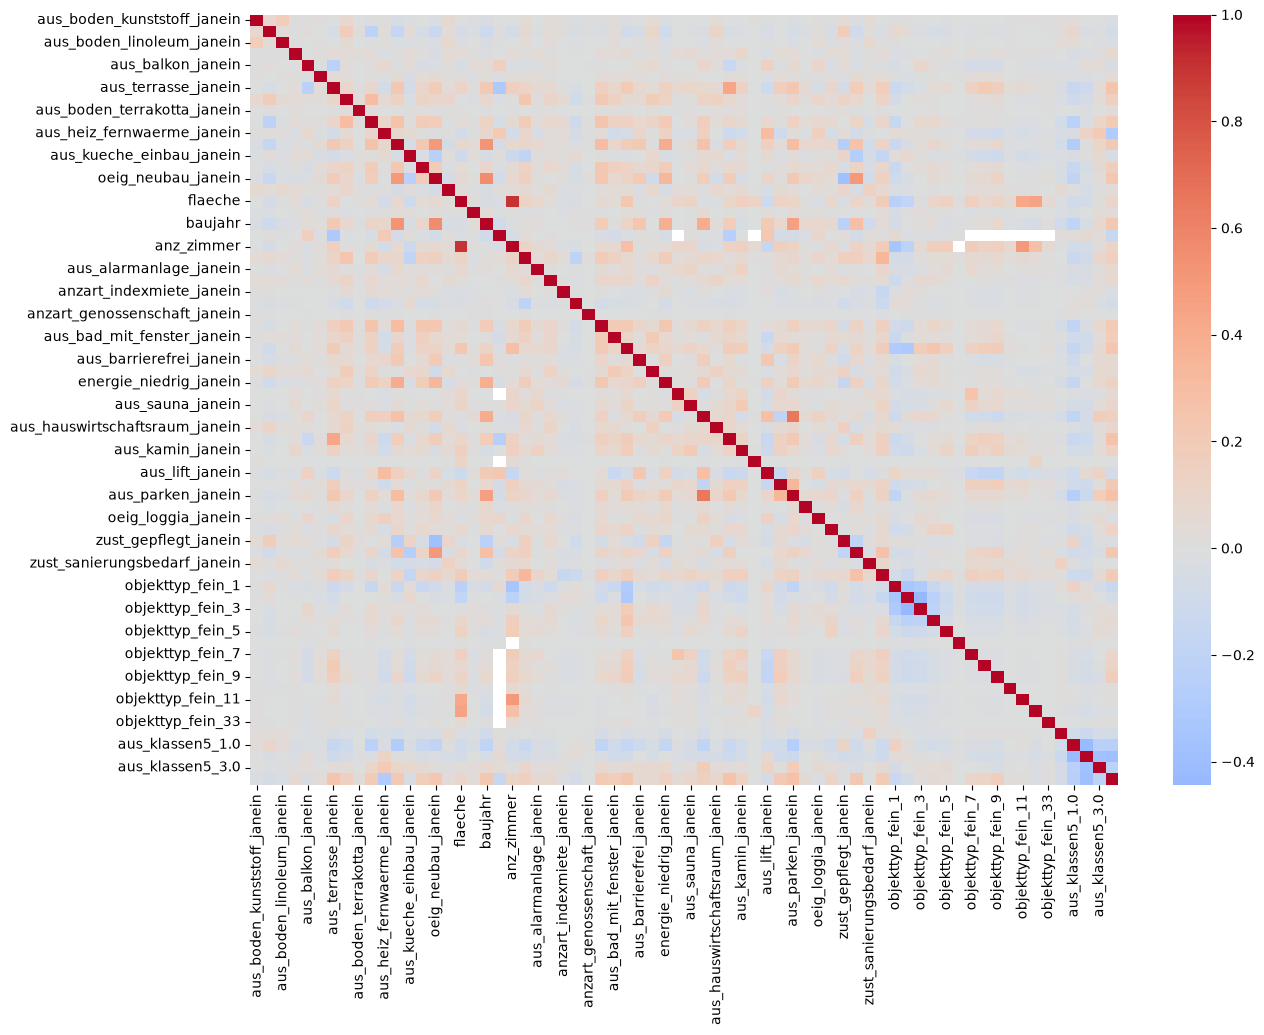

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)
plt.show()

корреляция почти нет, только горячий пол с новизной здания и размер с ценой и конкретным типом помещения.

In [19]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from utils import train_model, evaluate_model

In [20]:
target = "kosten_je_flaeche"

X = df.drop(columns=[target])
y = df[target]

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [22]:
class EMImputer:
    """
    Impute missing values with the EM algorithm under a multivariate
    Gaussian model.

    fit() estimates the mean and covariance from data with NaNs.
    transform() replaces each NaN with its conditional expectation
    given the observed values in the same row.

    Columns are standardized internally; a small ridge term keeps the
    covariance invertible (constant or collinear columns, e.g. one-hot).
    """

    def __init__(self, max_iter=100, tol=1e-4, ridge=1e-6):
        self.max_iter = max_iter
        self.tol = tol
        self.ridge = ridge

    def fit(self, X):
        Z, mask = self._standardize(X, fit=True)
        n, d = Z.shape

        mu = np.zeros(d)
        sigma = np.cov(np.where(mask, 0.0, Z), rowvar=False)

        for it in range(self.max_iter):
            Z_hat, C = self._e_step(Z, mask, mu, sigma)

            mu_new = Z_hat.mean(axis=0)
            diff = Z_hat - mu_new
            sigma_new = (diff.T @ diff + C) / n

            change = max(
                np.abs(mu_new - mu).max(),
                np.abs(sigma_new - sigma).max()
            )
            mu, sigma = mu_new, sigma_new

            if change < self.tol:
                break

        self.mean_ = mu
        self.covariance_ = sigma
        self.n_iter_ = it + 1

        return self

    def transform(self, X):
        Z, mask = self._standardize(X, fit=False)
        Z_hat, _ = self._e_step(Z, mask, self.mean_, self.covariance_)
        X_hat = Z_hat * self.scale_ + self.center_

        if isinstance(X, pd.DataFrame):
            return pd.DataFrame(X_hat, index=X.index, columns=X.columns)

        return X_hat

    def _standardize(self, X, fit):
        # via pandas so nullable "boolean" columns turn <NA> into NaN
        X = pd.DataFrame(X).astype(float).to_numpy()

        if fit:
            self.center_ = np.nanmean(X, axis=0)
            scale = np.nanstd(X, axis=0)
            self.scale_ = np.where(scale > 0, scale, 1.0)

        Z = (X - self.center_) / self.scale_

        return Z, np.isnan(Z)

    def _e_step(self, Z, mask, mu, sigma):
        """
        Fill missing entries with E[z_m | z_o] and accumulate the
        conditional covariance needed for the M-step.
        """

        d = Z.shape[1]
        Z_hat = np.where(mask, 0.0, Z)
        C = np.zeros((d, d))
        sigma_reg = sigma + self.ridge * np.eye(d)

        # rows with the same missingness pattern share the regression
        patterns, inverse = np.unique(mask, axis=0, return_inverse=True)
        inverse = inverse.ravel()

        for p, miss in enumerate(patterns):
            if not miss.any():
                continue

            rows = inverse == p
            obs = ~miss

            S_oo = sigma_reg[np.ix_(obs, obs)]
            S_mo = sigma_reg[np.ix_(miss, obs)]
            B = np.linalg.solve(S_oo, S_mo.T).T

            Z_hat[np.ix_(rows, miss)] = (
                mu[miss] + (Z[np.ix_(rows, obs)] - mu[obs]) @ B.T
            )
            C[np.ix_(miss, miss)] += rows.sum() * (
                sigma[np.ix_(miss, miss)] - B @ S_mo.T
            )

        return Z_hat, C

In [23]:
num_cols = X_train.select_dtypes(include="float").columns # non-boolean features; target is not in X

imputer = EMImputer().fit(X_train[num_cols]) # fit on train only
X_train[num_cols] = imputer.transform(X_train[num_cols])
X_test[num_cols] = imputer.transform(X_test[num_cols])

print(list(num_cols), "EM iterations:", imputer.n_iter_)

['flaeche', 'baujahr', 'etage', 'anz_zimmer'] EM iterations: 44


## Линейная модель

In [24]:
from models import linear
model = linear.build_model()

training_result = train_model(
    model,
    X_train,
    y_train
)
best_model = training_result["model"]
training_result

{'model': LinearRegression(),
 'best_params': None,
 'cv_metrics': None,
 'search': None}

In [25]:
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'rmse': np.float64(4390.538932011605),
 'mae': 3500.9781040105486,
 'r2': 0.2886778311394518,
 'predictions': array([2434.40737811, 8505.51395088, 7191.88281806, ..., 5499.69817789,
         861.81598457, 3420.53960909], shape=(23902,))}

In [26]:
print(y.describe())

count    119510.000000
mean       4201.682528
std        5196.318730
min           3.000000
25%          20.100000
50%          27.790000
75%        8481.392500
max       29914.530000
Name: kosten_je_flaeche, dtype: float64


## Дерево

In [27]:
%%time
from models import regression_tree
model = regression_tree.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=regression_tree.get_param_grid(),
    cv=5
)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   4.6s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   4.8s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   5.8s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   6.6s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=10, splitter=best; total time=   4.5s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=10, splitter=best; total time=   4.3s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   6.7s
[CV] END criterion=squared_error, max_depth=None, min_samples

In [28]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 50, 'splitter': 'best'}
{'rmse': np.float64(4303.367973669728), 'rmse_std': np.float64(48.63244471814055), 'mae': np.float64(3285.569595003805), 'mae_std': np.float64(24.061989668423855), 'r2': np.float64(0.31343875357234047), 'r2_std': np.float64(0.006700901815399591)}


{'rmse': np.float64(4272.855509097742),
 'mae': 3261.581940701768,
 'r2': 0.32629915369108065,
 'predictions': array([2826.18746976, 6478.55430657, 3763.765     , ..., 4171.75675166,
        1360.53706433, 1953.04555651], shape=(23902,))}

## Случайный лес

In [29]:
%%time
from models import random_forest
model = random_forest.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=random_forest.get_param_grid(),
    cv=5
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
[CV] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=25; total time=  53.3s
[CV] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=25; total time=  58.6s
[CV] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=25; total time= 1.1min
[CV] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=25; total time= 1.1min
[CV] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=25; total time= 1.2min
[CV] END ccp_alpha=0.0, criterion=squared_error, max_depth=None, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=1

In [30]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 300}
{'rmse': np.float64(3883.7612457770724), 'rmse_std': np.float64(45.55504939924144), 'mae': np.float64(2880.2935849302066), 'mae_std': np.float64(19.21903489012359), 'r2': np.float64(0.44078525440754773), 'r2_std': np.float64(0.007254543469965311)}


{'rmse': np.float64(3829.22469904355),
 'mae': 2817.884180617011,
 'r2': 0.4589313365875395,
 'predictions': array([ 302.84254783, 5029.6253593 , 9789.66747894, ..., 7549.17873368,
         453.6232769 ,  812.98325888], shape=(23902,))}

## Бустинг

In [31]:
%%time
from models import gradient_boosting
model = gradient_boosting.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=gradient_boosting.get_param_grid(),
    cv=5
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=0.8; total time=  22.3s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=0.8; total time=  23.1s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=0.8; total time=  24.6s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=0.8; total time=  24.8s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=0.8; total time=  25.0s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=1.0; total time=  28.8s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=1.0; total time=  28.3s
[CV] END learning_rate=0.05, max_depth=2, min_samples_leaf=1, n_estimators=100, subsample=1.0; total time=  30.2s
[CV] END learning_rate=0.0

KeyboardInterrupt: 

In [ ]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

In [ ]:
%%time
from utils import train_model, evaluate_model
from models import xgboost
import cupy as cp

X_train_gpu = cp.asarray(
    X_train.astype(np.float32).to_numpy()
)

y_train_gpu = cp.asarray(
    y_train.astype(np.float32).to_numpy()
)

X_test_gpu = cp.asarray(
    X_test.astype(np.float32).to_numpy()
)
    
y_test_gpu = cp.asarray(
    y_test.astype(np.float32).to_numpy()
)

model = xgboost.build_model()

# training_result = train_model(
#     model,
#     X_train,
#     y_train,
#     param_grid=xgboost.get_param_grid(),
#     cv=5,
#     n_jobs=1
# )

In [ ]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

## KNN

In [ ]:
%%time
from models import knn

model = knn.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=knn.get_param_grid(),
    cv=5,
    n_jobs=1
)

In [ ]:
print(training_result["best_params"])
print(training_result["cv_metrics"])

best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result